# 04 Kumo Tabular

**The question.** NVIDIA Kumo Tabular is a model pretrained on many tables. It is not trained on our data: it is handed a table of known prices and predicts new ones from it in one pass. Does it price bid items better than the models of notebook 03, on the same test?

**What we did.** Kumo was given every cleaned training bid before 2024 (**10,091 rows**, with the same facts the baselines see) and priced all 4,507 test items. It ran on this Mac's processor with NVIDIA's small model, downloaded once from Hugging Face. Settings were chosen on 2023 bids: one shared table beat separate tables per item family, and the small model beat the medium one at a third of the time. We then checked the results in plain terms (stage 12).

**What we found.**
- Kumo misses by **40.2%**, against 43.4% for LightGBM, 46.1% for XGBoost and 55.0% for the median, and is best in **13 of 18** item families. It priced every test item in about 11 seconds.
- **Where it loses:** LightGBM is better on earthwork, structural concrete and minor concrete, and the median on bridge rehabilitation.
- **Why single items miss by about 40%:** the low bid itself is noisy. On the same line, the second-lowest bidder's price differs from the low bidder's by a median of **27.5%**. Lump sums are the hardest (Kumo 58.6%), items bid per unit much easier (34.4%).
- **All frozen models drift high.** Kumo is 7% over the low bid in 2024 and 24% over in 2026; XGBoost 45% over in 2026. They carry 2023 prices forward with the statewide cost index, which rose about 29% from late 2023 to early 2026, while these low bids rose much less. Notebook 05 fixes this by letting the models see recent bids.

The full reports: [`outputs/11_kumo_tabular/`](../outputs/11_kumo_tabular/README.md) and [`outputs/12_sanity_check/`](../outputs/12_sanity_check/README.md).

## Setup

This loads the project's own code (`src/bidlens/analysis/stages.py`), which reads the results each stage already saved in `outputs/`. Nothing is recomputed here, so the notebook runs in seconds on a fresh copy of the repository, with no database and no model downloads.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
import pandas as pd

from bidlens.analysis import stages as s

pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.max_open_warning"] = 0

## Overall, on the same test as notebook 03

In [2]:
s.kumo_overall()

,Method,Median miss,Within 15% of the low bid
0,Historical median,55.0%,15.3%
1,XGBoost,46.1%,18.0%
2,LightGBM,43.4%,19.4%
3,Kumo Tabular,40.2%,20.5%


## By item family

Same chart as in notebook 03, with Kumo added in blue. Kumo is shortest on most families, often by several points (general and overhead, striping, concrete pavement, piling). The families where another method wins are the honest exceptions listed above.

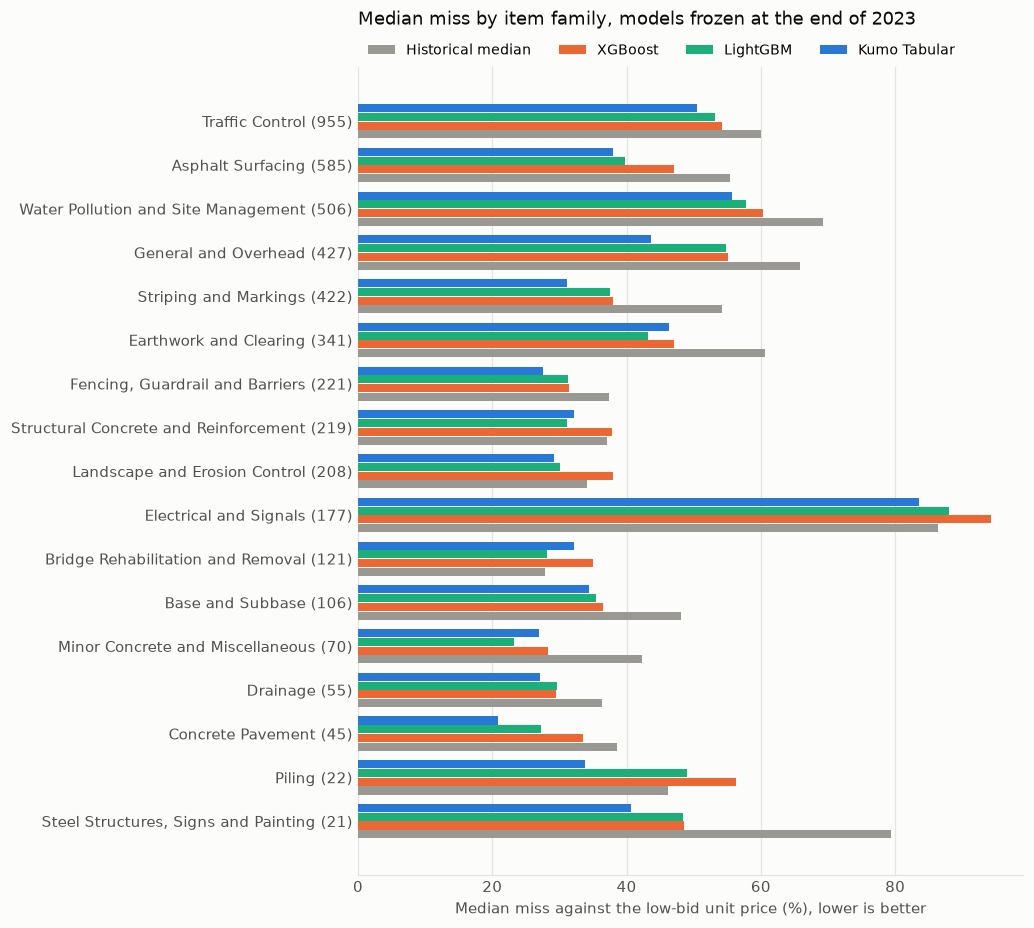

In [3]:
breakdown = s.error_breakdown()
fam = breakdown[breakdown["by"] == "family"].rename(columns={"group": "family"})
fig = s.chart_family_mdape(
    fam, list(s.METHODS), "Median miss by item family, models frozen at the end of 2023"
)
s.save(fig, "mdape_by_family", s.S11)
plt.show()

## Why single items miss: noise in the low bid itself

Bars show the median miss by kind of item. The dashed line is a natural floor: how far the *second-lowest* bidder's unit price sits from the low bidder's on the same line. Contractors spread costs across items differently, so even a real competitive bid misses the low bid by 27.5% at the median. Lump sums (mobilization, traffic control) and quantities far from the item's usual size are the hardest. On items bid at a typical quantity, the best models come within a few points of the floor.

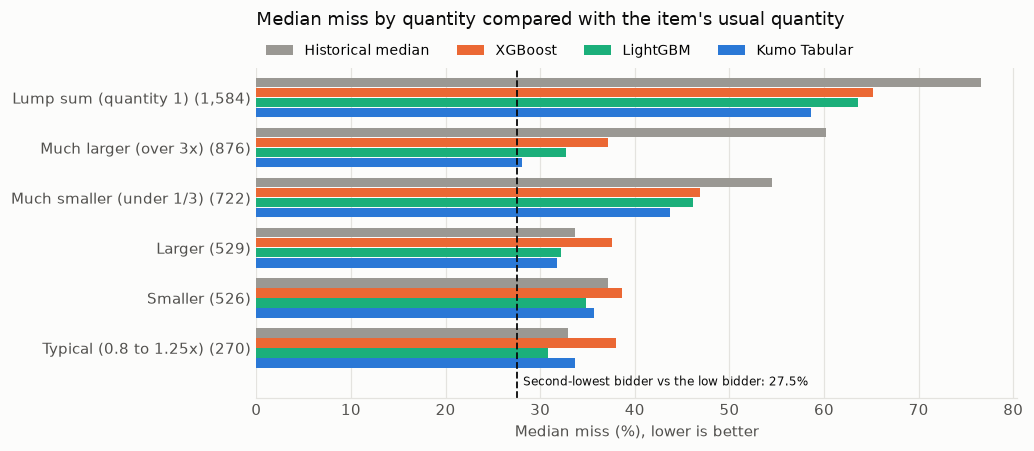

In [4]:
fig = s.chart_kinds(breakdown, s.noise_floor())
s.save(fig, "miss_by_quantity", s.S12)
plt.show()

## The models drift high as the years pass

Each bar is the median of *prediction / low bid − 1* for one year: above zero means the method priced too high. The median of recent bids stays close. The models, frozen at the end of 2023, drift further above the low bid every year. This is the problem notebook 05 solves.

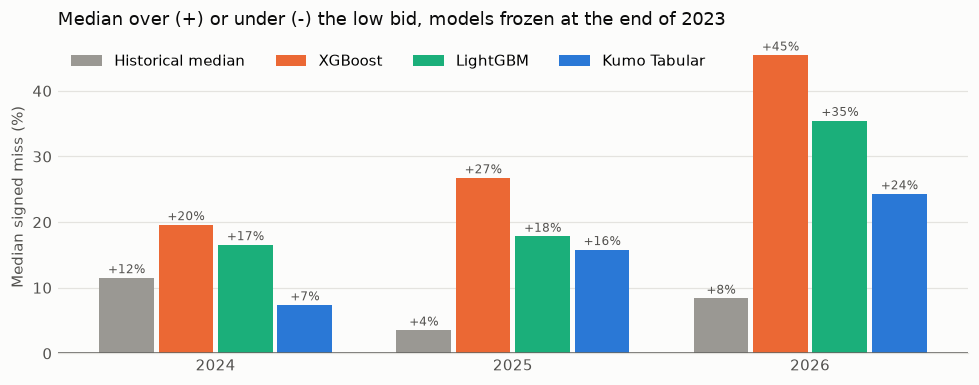

In [5]:
drift = s.frozen_drift()
fig = s.chart_by_year(
    drift,
    list(s.METHODS),
    "Median over (+) or under (-) the low bid, models frozen at the end of 2023",
    "Median signed miss (%)",
    signed=True,
)
s.save(fig, "drift_by_year", s.S12)
plt.show()

## Save and next

This adds the charts above to `outputs/11_kumo_tabular/` and `outputs/12_sanity_check/`. To recompute: `uv run python -m bidlens.pricing.kumo`, then `uv run python -m bidlens.pricing.sanity`. PyTorch (Kumo) and the tree libraries must run in separate Python processes on macOS, which is why each model has its own script.

**Next:** *05 Model comparison*, the headline: BidLens against Caltrans' engineer's estimate.

In [6]:
s.note_in_readme(s.S11, "04_kumo_tabular.ipynb")
s.note_in_readme(s.S12, "04_kumo_tabular.ipynb")
sorted(p.name for d in (s.S11, s.S12) for p in d.glob("nb_*.png"))

['nb_drift_by_year.png', 'nb_mdape_by_family.png', 'nb_miss_by_quantity.png']